Load Dataset

In [1]:
import pandas as pd

malware_df = pd.read_csv('real_malware_v1.csv')
benign_df = pd.read_csv('real_legitimate_v1.csv')

print("Malware:", malware_df.shape)
print("Benign :", benign_df.shape)

Malware: (41382, 484)
Benign : (36755, 484)


Gabungkan Dataset

In [2]:
df = pd.concat([malware_df, benign_df], ignore_index=True).copy()
print(df.shape)
print(df['Malware'].value_counts())

(78137, 484)
Malware
1    41382
0    36755
Name: count, dtype: int64


Drop Kolom Non-Fitur (Identifier & Metadata)

In [3]:
df = df.drop(columns=['Package', 'sha256', 'EarliestModDate', 'HighestModDate', 'MalFamily'])
print(df.shape)
print(df.dtypes.value_counts())

(78137, 479)
int64      469
float64     10
Name: count, dtype: int64


Cek & Handling Missing Value

In [4]:
print("Total missing value:", df.isnull().sum().sum())

before = df.shape[0]
df = df.dropna()
after = df.shape[0]
print(f"Dropped {before - after} baris, sisa: {after}")

Total missing value: 5779
Dropped 643 baris, sisa: 77494


Deduplication

In [5]:
before = df.shape[0]
df = df.drop_duplicates()
after = df.shape[0]
print(f"Duplikat dihapus: {before - after} ({(before-after)/before*100:.1f}%)")
print(f"Shape akhir: {df.shape}")

Duplikat dihapus: 36 (0.0%)
Shape akhir: (77458, 479)


Memisahkan Fitur & Label

In [6]:
label_col = 'Malware'
feature_cols = [c for c in df.columns if c != label_col]

X = df[feature_cols]
y = df[label_col]

print("Jumlah fitur:", len(feature_cols))
print("Distribusi label:\n", y.value_counts())

Jumlah fitur: 478
Distribusi label:
 Malware
1    40978
0    36480
Name: count, dtype: int64


In [7]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import RobustScaler
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, classification_report, confusion_matrix)
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier

# ---------------- KONFIGURASI ----------------
LABEL_COL     = 'Malware'
USE_SMOTE     = True        # False untuk eksperimen ablation tanpa SMOTE
FAST_MODE     = False       # True = n_estimators dikecilkan, hanya untuk uji cepat (smoke test)
RANDOM_STATE  = 42
# ---------------------------------------------

In [8]:
X_raw = df[feature_cols].values.astype(float)
y     = df[LABEL_COL].values.astype(int)

# Log1p stateless (tidak belajar dari data), aman sebelum split. Rumus paper: x' = ln(1 + |x|)
X_log = np.log1p(np.abs(X_raw))
print("X_log:", X_log.shape, "| y:", y.shape, "| kelas:", np.unique(y))

X_log: (77458, 478) | y: (77458,) | kelas: [0 1]


In [9]:
X_tr, X_te, y_tr, y_te = train_test_split(
    X_log, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)

print("Train:", X_tr.shape, np.bincount(y_tr))
print("Test :", X_te.shape, np.bincount(y_te))

Train: (61966, 478) [29184 32782]
Test : (15492, 478) [7296 8196]


In [10]:
scaler = RobustScaler().fit(X_tr)
X_tr_s = scaler.transform(X_tr)
X_te_s = scaler.transform(X_te)

if USE_SMOTE:
    X_tr_sm, y_tr_sm = SMOTE(random_state=RANDOM_STATE, k_neighbors=5).fit_resample(X_tr_s, y_tr)
else:
    X_tr_sm, y_tr_sm = X_tr_s, y_tr

print(f"USE_SMOTE = {USE_SMOTE}")
print("Train sebelum:", X_tr_s.shape, np.bincount(y_tr))
print("Train sesudah:", X_tr_sm.shape, np.bincount(y_tr_sm))

USE_SMOTE = True
Train sebelum: (61966, 478) [29184 32782]
Train sesudah: (65564, 478) [32782 32782]


In [11]:
def get_models():
    n_big  = 100 if FAST_MODE else 1000
    n_tree = 100 if FAST_MODE else 700
    return {
        'LightGBM': LGBMClassifier(
            n_estimators=n_big, max_depth=8, learning_rate=0.03,
            num_leaves=127, subsample=0.8, colsample_bytree=0.7,
            min_child_samples=20, reg_alpha=0.05, reg_lambda=0.5,
            class_weight='balanced', random_state=RANDOM_STATE, n_jobs=-1, verbose=-1),
        'XGBoost': XGBClassifier(
            n_estimators=n_big, max_depth=7, learning_rate=0.03,
            subsample=0.8, colsample_bytree=0.7, min_child_weight=5,
            reg_alpha=0.05, reg_lambda=0.5, eval_metric='logloss',
            random_state=RANDOM_STATE, n_jobs=-1),
        'RandomForest': RandomForestClassifier(
            n_estimators=n_tree, max_features='sqrt', class_weight='balanced',
            random_state=RANDOM_STATE, n_jobs=-1),
        'ExtraTrees': ExtraTreesClassifier(
            n_estimators=n_tree, class_weight='balanced',
            random_state=RANDOM_STATE, n_jobs=-1),
    }

def evaluate(y_true, y_pred):
    return {
        'acc':  accuracy_score(y_true, y_pred),
        'prec': precision_score(y_true, y_pred, average='weighted', zero_division=0),
        'rec':  recall_score(y_true, y_pred, average='weighted', zero_division=0),
        'f1':   f1_score(y_true, y_pred, average='weighted', zero_division=0),
    }

def hard_vote(pred_list):
    """Hard voting untuk label biner 0/1. Jika seri (2-2 pada 4 model) -> kelas 0, sama seperti stats.mode."""
    votes = np.stack(pred_list, axis=1)
    return (votes.sum(axis=1) * 2 > votes.shape[1]).astype(int)

print("Model terdefinisi:", list(get_models().keys()), "| FAST_MODE =", FAST_MODE)

Model terdefinisi: ['LightGBM', 'XGBoost', 'RandomForest', 'ExtraTrees'] | FAST_MODE = False


In [12]:
models   = get_models()
preds_ho = {}
results_ho = {}

for name, mdl in models.items():
    print(f"Training {name} ...")
    mdl.fit(X_tr_sm, y_tr_sm)
    preds_ho[name] = mdl.predict(X_te_s)
    results_ho[name] = evaluate(y_te, preds_ho[name])

ensembles = {
    'Ens(RF+ET+LGB)':     ['RandomForest', 'ExtraTrees', 'LightGBM'],
    'Ens(RF+ET+XGB)':     ['RandomForest', 'ExtraTrees', 'XGBoost'],
    'Ens(RF+ET+LGB+XGB)': ['RandomForest', 'ExtraTrees', 'LightGBM', 'XGBoost'],
}
for ens_name, members in ensembles.items():
    p = hard_vote([preds_ho[m] for m in members])
    preds_ho[ens_name] = p
    results_ho[ens_name] = evaluate(y_te, p)

ho_table = (pd.DataFrame(results_ho).T
            .rename(columns={'acc': 'Acc', 'prec': 'Prec', 'rec': 'Rec', 'f1': 'F1'})
            .sort_values('Acc', ascending=False))
print("\nHASIL HOLD-OUT (80:20) — KronoDroid")
print((ho_table * 100).round(2).astype(str) + '%')

Training LightGBM ...
Training XGBoost ...
Training RandomForest ...
Training ExtraTrees ...

HASIL HOLD-OUT (80:20) — KronoDroid
                       Acc    Prec     Rec      F1
XGBoost             99.61%  99.61%  99.61%  99.61%
LightGBM            99.61%  99.61%  99.61%  99.61%
Ens(RF+ET+LGB)      99.58%  99.58%  99.58%  99.58%
Ens(RF+ET+LGB+XGB)  99.58%  99.58%  99.58%  99.58%
Ens(RF+ET+XGB)      99.57%  99.57%  99.57%  99.57%
RandomForest        99.48%  99.48%  99.48%  99.48%
ExtraTrees          99.37%  99.37%  99.37%  99.37%


In [13]:
def make_pipeline(model):
    steps = [('scaler', RobustScaler())]
    if USE_SMOTE:
        steps.append(('smote', SMOTE(random_state=RANDOM_STATE, k_neighbors=5)))
    steps.append(('clf', model))
    return ImbPipeline(steps)

cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_results, cv_fold_acc = {}, {}

for name, mdl in get_models().items():
    print(f"5-Fold CV: {name} ...")
    fold_metrics = []
    for fold, (tr_idx, te_idx) in enumerate(cv5.split(X_log, y), 1):
        pipe = make_pipeline(clone(mdl))
        pipe.fit(X_log[tr_idx], y[tr_idx])          # scaler + SMOTE hanya melihat data training fold
        fold_metrics.append(evaluate(y[te_idx], pipe.predict(X_log[te_idx])))
    fm = pd.DataFrame(fold_metrics)
    cv_fold_acc[name] = fm['acc'].round(4).tolist()
    cv_results[name] = {'CV Acc': fm['acc'].mean(), 'CV Std': fm['acc'].std(ddof=0),
                        'CV Prec': fm['prec'].mean(), 'CV Rec': fm['rec'].mean(), 'CV F1': fm['f1'].mean()}
    print(f"   Acc {fm['acc'].mean():.4f} ± {fm['acc'].std(ddof=0):.4f} | per-fold: {cv_fold_acc[name]}")

cv_table = pd.DataFrame(cv_results).T.sort_values('CV Acc', ascending=False)
print("\nHASIL 5-FOLD CV — KronoDroid")
print(cv_table.round(4))

5-Fold CV: LightGBM ...
   Acc 0.9960 ± 0.0003 | per-fold: [0.9956, 0.9963, 0.9962, 0.9958, 0.9959]
5-Fold CV: XGBoost ...
   Acc 0.9958 ± 0.0004 | per-fold: [0.9952, 0.996, 0.9964, 0.9958, 0.9959]
5-Fold CV: RandomForest ...
   Acc 0.9947 ± 0.0005 | per-fold: [0.9948, 0.9952, 0.9949, 0.9948, 0.9939]
5-Fold CV: ExtraTrees ...
   Acc 0.9934 ± 0.0009 | per-fold: [0.9943, 0.9936, 0.9931, 0.9941, 0.9918]

HASIL 5-FOLD CV — KronoDroid
              CV Acc  CV Std  CV Prec  CV Rec   CV F1
LightGBM      0.9960  0.0003   0.9960  0.9960  0.9960
XGBoost       0.9958  0.0004   0.9958  0.9958  0.9958
RandomForest  0.9947  0.0005   0.9947  0.9947  0.9947
ExtraTrees    0.9934  0.0009   0.9934  0.9934  0.9934


In [14]:
# Angka dari paper sebelumnya (CICMalDroid2020, 5 kelas): Tabel III (hold-out) dan Tabel IV (CV)
paper_ho = {'LightGBM': 0.9636, 'XGBoost': 0.9618, 'ExtraTrees': 0.9549, 'RandomForest': 0.9545,
            'Ens(RF+ET+LGB+XGB)': 0.9592, 'Ens(RF+ET+LGB)': 0.9571, 'Ens(RF+ET+XGB)': 0.9571}
paper_cv = {'LightGBM': 0.9558, 'XGBoost': 0.9551, 'RandomForest': 0.9501, 'ExtraTrees': 0.9493}

rows = []
for name in ho_table.index:
    rows.append({
        'Model': name,
        'Hold-out (paper)':      paper_ho.get(name),
        'Hold-out (KronoDroid)': results_ho[name]['acc'],
        'CV (paper)':            paper_cv.get(name),
        'CV (KronoDroid)':       cv_results[name]['CV Acc'] if name in cv_results else None,
    })
cmp_df = pd.DataFrame(rows).set_index('Model')
cmp_df['Δ Hold-out'] = cmp_df['Hold-out (KronoDroid)'] - cmp_df['Hold-out (paper)']
cmp_df['Δ CV']       = cmp_df['CV (KronoDroid)'] - cmp_df['CV (paper)']
print(cmp_df.round(4))

best_ho = ho_table.index[0]
best_cv = cv_table.index[0]
print(f"\nModel terbaik hold-out : {best_ho}")
print(f"Model terbaik 5-Fold CV: {best_cv}")
print("LightGBM masih terbaik di keduanya?", best_ho == 'LightGBM' and best_cv == 'LightGBM')

                    Hold-out (paper)  Hold-out (KronoDroid)  CV (paper)  \
Model                                                                     
XGBoost                       0.9618                 0.9961      0.9551   
LightGBM                      0.9636                 0.9961      0.9558   
Ens(RF+ET+LGB)                0.9571                 0.9958         NaN   
Ens(RF+ET+LGB+XGB)            0.9592                 0.9958         NaN   
Ens(RF+ET+XGB)                0.9571                 0.9957         NaN   
RandomForest                  0.9545                 0.9948      0.9501   
ExtraTrees                    0.9549                 0.9937      0.9493   

                    CV (KronoDroid)  Δ Hold-out    Δ CV  
Model                                                    
XGBoost                      0.9958      0.0343  0.0407  
LightGBM                     0.9960      0.0325  0.0402  
Ens(RF+ET+LGB)                  NaN      0.0387     NaN  
Ens(RF+ET+LGB+XGB)              Na

              precision    recall  f1-score   support

      Benign     0.9948    0.9968    0.9958      7296
     Malware     0.9972    0.9954    0.9963      8196

    accuracy                         0.9961     15492
   macro avg     0.9960    0.9961    0.9960     15492
weighted avg     0.9961    0.9961    0.9961     15492



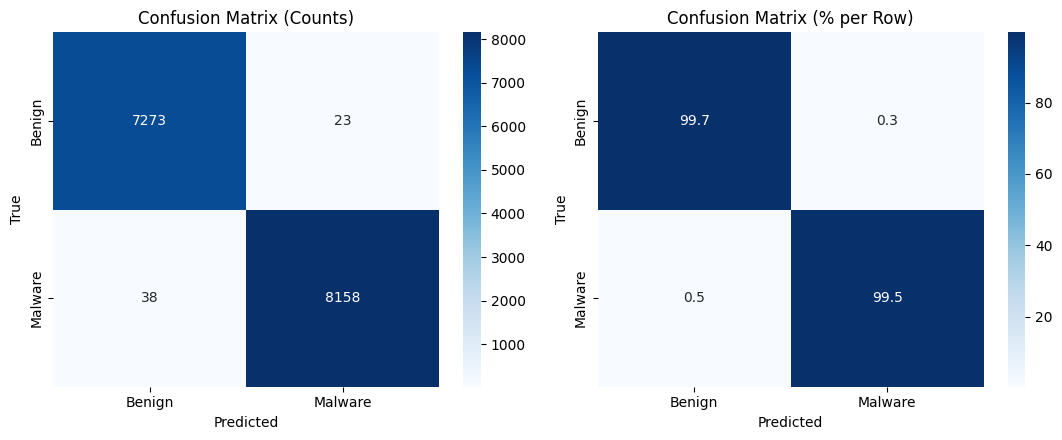


Top 10 feature importance (LightGBM, split count):
Detection_Ratio    4892
TimesSubmitted     4793
FilesInsideAPK     4295
CFileSize          4007
UFileSize          4006
Activities         2667
futex              2495
write              2447
clock_gettime      1958
writev             1918
dtype: int32

Irisan dengan top-10 paper CICMalDroid2020: 4 fitur -> ['futex', 'write', 'clock_gettime', 'writev']


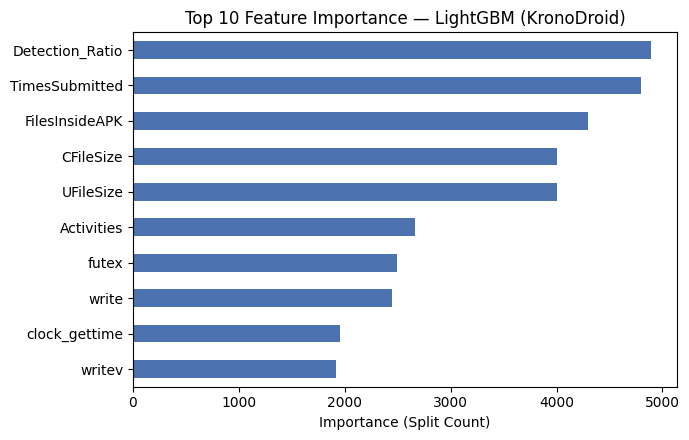

In [15]:
lgb_best = models['LightGBM']
y_pred_lgb = preds_ho['LightGBM']
class_names = ['Benign', 'Malware']

print(classification_report(y_te, y_pred_lgb, target_names=class_names, digits=4))

cm = confusion_matrix(y_te, y_pred_lgb)
cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names,
            yticklabels=class_names, ax=axes[0])
axes[0].set_title('Confusion Matrix (Counts)'); axes[0].set_xlabel('Predicted'); axes[0].set_ylabel('True')
sns.heatmap(cm_norm * 100, annot=True, fmt='.1f', cmap='Blues', xticklabels=class_names,
            yticklabels=class_names, ax=axes[1])
axes[1].set_title('Confusion Matrix (% per Row)'); axes[1].set_xlabel('Predicted'); axes[1].set_ylabel('True')
plt.tight_layout()
plt.savefig('kronodroid_confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()

# Feature importance (split count, sama seperti Fig. 5 di paper sebelumnya)
imp = pd.Series(lgb_best.feature_importances_, index=feature_cols).sort_values(ascending=False)
top10 = imp.head(10)
print("\nTop 10 feature importance (LightGBM, split count):")
print(top10)

paper_top10 = ['writev', 'mprotect', 'brk', 'futex', 'getpriority', 'ioctl',
               'sigprocmask', 'write', 'pread64', 'clock_gettime']
overlap = [f for f in top10.index if f in paper_top10]
print(f"\nIrisan dengan top-10 paper CICMalDroid2020: {len(overlap)} fitur -> {overlap}")

plt.figure(figsize=(7, 4.5))
top10[::-1].plot(kind='barh', color='#4C72B0')
plt.xlabel('Importance (Split Count)'); plt.title('Top 10 Feature Importance — LightGBM (KronoDroid)')
plt.tight_layout()
plt.savefig('kronodroid_feature_importance.png', dpi=150, bbox_inches='tight')
plt.show()